## To run simulations iteratively

In [ ]:
## Code to iteratively run simulations

using NPZ,Interpolations,Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot

folder_path = "./functions_run_simulations/"
for file in readdir(folder_path)
    if endswith(file, ".jl")
        include(joinpath(folder_path, file))
    end
end

# List of days to process
days=[ 1, 3] # 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

# Load static neuron properties
JLD2.@load "Data_MN_Model/Data_final/Subjects_optim_process/VthCa_TA_subject1_gamma1.jld2" VthCa_newTA
nr_s = length(VthCa_newTA)

# Precompute neuron parameters (as before)
rheobase_S = LinRange(3.5, 6.5, nr_s) .+ rand(Normal(0.0, 0.05), nr_s)
rs_S = LinRange(38.75, 41.25, nr_s) ./ 10000
ls_S = LinRange(77.5, 82.5, nr_s) ./ 10000
rms_S = LinRange(1.15, 1.05, nr_s) .* 1000
rd_S = LinRange(20.75, 31.25, nr_s) ./ 10000
ld_S = LinRange(5500., 6800., nr_s) ./ 10000
rmd_S = LinRange(14.4, 10.7, nr_s) .* 1000

max_gna = 30.0
max_gkf_S = ones(nr_s) * 4
max_gks_S = LinRange(16, 25, nr_s)
max_gca_S = LinRange(0.038, 0.029, nr_s)

αm = ones(nr_s) * 22.0
βm = ones(nr_s) * 13.0
αh_S = ones(nr_s) * 0.5
βh_S = ones(nr_s) * 4
αn_S = ones(nr_s) * 1.5
βn_S = ones(nr_s) * 0.1
αq_S = ones(nr_s) * 1.5
βq_S = LinRange(0.025, 0.038, nr_s)
αp_D = 0.008
βp_D = LinRange(0.014, 0.016, nr_s)

Vthca_S = VthCa_newTA[1, :]
Apeak_S = LinRange(0.103, 0.123, nr_s)
tpeak_S = LinRange(110., 100., nr_s)
tetanic_S = LinRange(0.393, 0.491, nr_s)

γh = ones(nr_s)
IF = LinRange(1., 1., nr_s)

EL = 0; ENa = 120; ECa = 140; EK = -10; Ee = 70; Ei = -16
Ge = 0.6; Gi = 0.5
Vd0 = 0.; Vs0 = 0.;
rp = 5.0
pd=1; 

const step = 0.05
_int(num) = floor(Int, num)

# Precompute neuron properties
MN_list = []
for i in 1:nr_s
    gls = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6
    gld = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6
    gc = ((2/(((70*ld_S[i])/(π*rd_S[i]^2)) + ((70*ls_S[i])/(π*rs_S[i]^2)))))*1e6
    rn = 1 / (gls + ((gld*gc)/(gld+gc)))
    Vth = round(rn * rheobase_S[i], digits=2)
    cs = 2*π*ls_S[i]*rs_S[i]*1*1e3
    cd = 2*π*ld_S[i]*rd_S[i]*1*1e3
    gna = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3
    gkf = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3
    gks = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3
    gca = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3

    S_MN = Dict(:Cs => cs, :Cd => cd, :Irh => rheobase_S[i], :gc => gc,:gNa => gna, :gKs => gks, :gKf => gkf, :gCa => gca,  :gld => gld, :gls => gls, :αp => αp_D, :βp => βp_D[i], :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i],:αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i],:Vth => Vth, :VthCa => Vthca_S[i], :Rn => rn,:Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh => γh[i],"type" => "All Type")
    push!(MN_list, S_MN)
end
MNs = MN_list

for day in days # Loop over days

    day_str = lpad(day, 2, '0')  # Format day number with leading zero
    println("\nProcessing Day$day_str")

    # Load and resample force profile
    tr = npzread("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1/force_S1111_Day$(day_str).npy")
    sim_length = length(tr)
    interp = LinearInterpolation(1:sim_length, tr)
    resampled_indices = range(1, sim_length, length=Int(round(sim_length/2048))*1000)
    tr = interp(resampled_indices)
    sim_length = length(tr)
    amplitude = maximum(tr)

    # Simulation settings
    global tspan = 0:0.05:sim_length
    sim_time = _int(sim_length / 0.05)

    # Initialize state variables
    m=0.0; h=1.0; n=0.0; q=0.0; p=0.0; m0=0.0; h0=1.0; n0=0.0; q0=0.0; p0=0.0
    t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
    global pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s)

    global spike_arr = zeros((nr_s, sim_time))
    global vs_arr = zeros((nr_s, sim_time))
    global pt_arr = zeros((nr_s, sim_time))
    global mt_arr = zeros((nr_s, sim_time))
    global ht_arr = zeros((nr_s, sim_time))
    global nt_arr = zeros((nr_s, sim_time))
    global qt_arr = zeros((nr_s, sim_time))

    global commoninput = tr
    global inh_input = fill(0.00001 * amplitude, sim_length)
    global full_input = zeros((nr_s, sim_length))
    global independantnoise = zeros((nr_s, sim_length))

    # Run simulation
    @time spike_array, vs_array, pt_arr = run_sim()

    # Save results using JLD2.save
    output_file = "Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S1/DR_rep_trial_$(day_str)_scaled11.jld2"
    JLD2.save(output_file, Dict("spike_array" => spike_array))
    println("Saved simulation results for Day$day_str to $output_file")
end


InexactError: InexactError: Int64(21.125)

## This code is to produce the firing rates for each motoneuron to create the histograms

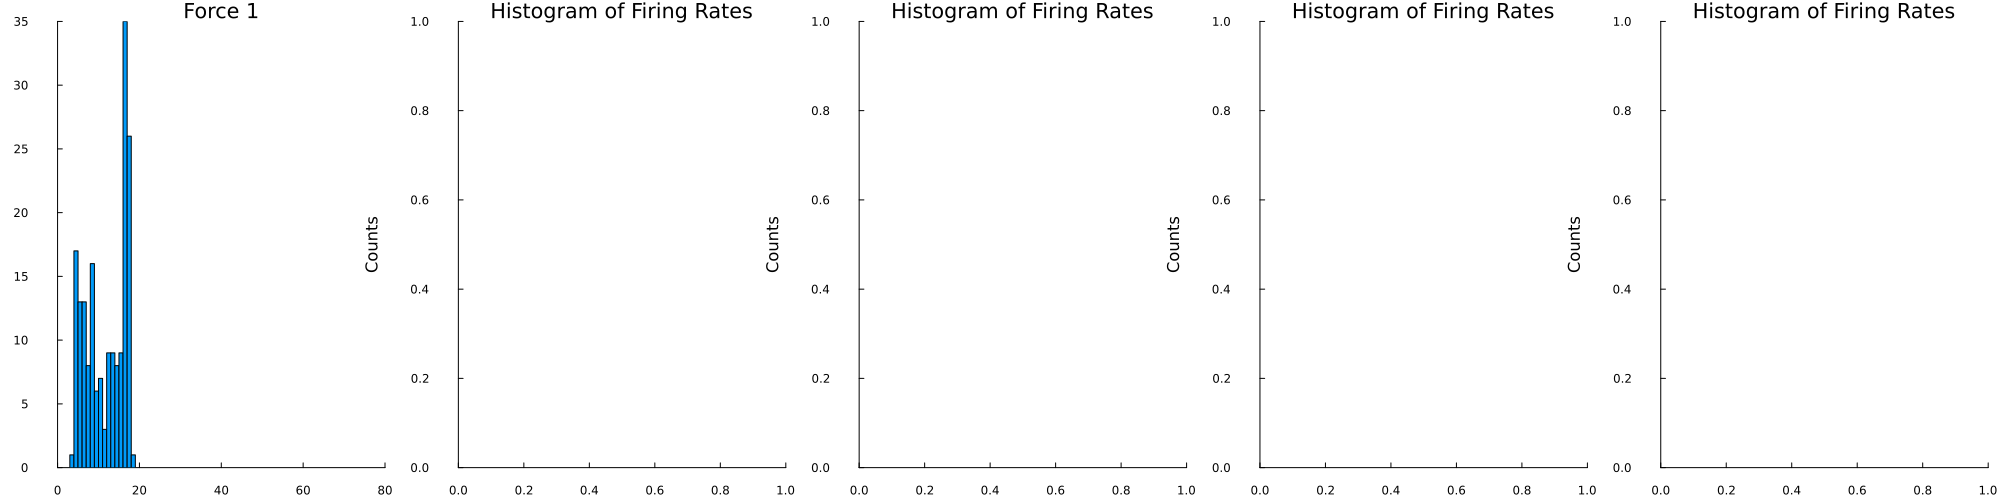

In [ ]:
using JLD2
using Plots

# Set sampling rate
sampling_rate = 20000  # Hz

# List of force conditions
force_conditions = [ 1] #, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

# force_conditions = [02, 03, 04, 07,  13]
# force_conditions = [01, 02,03, 04, 05,07,10, 11, 12, 13, 14]
# force_conditions = [01,03,07, 08, 09, 10, 11, 12, 13, 14]

# force_conditions = [01,03,04, 05, 06, 07,08,09,[10, 11, 12, 13, 14]
# force_conditions = [01,02,03,04,05,06,07, 08, 09, 10]

# Create a figure with subplots (4 columns)
n_plots = length(force_conditions)
n_rows = ceil(Int, n_plots / 5)  # Calculate the number of rows based on 4 columns

# Create a plot grid with 4 columns
p = Plots.plot(legend=false, grid=false, xlabel="Firing Rate (Hz)", ylabel="Counts", title="Histogram of Firing Rates", layout=(n_rows, 5), size=(2000, 500))

# Loop through each force condition
for (i, force) in enumerate(force_conditions)
    day_str = lpad(force, 2, '0')  # Format day number with leading zero
    
    # Construct the file path for the current force condition
    force_file = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S1/DR_rep_trial_$(day_str)_scaled09.jld2"


    # Load the spike array for the current force condition
    JLD2.@load force_file spike_array

    # Initialize array for storing firing rates for this file
    all_rates = []

    # Calculate rates for each motor unit
    # Initialize array for storing average firing rates (one per motor unit)
    avg_rates_per_neuron = Float64[]

    for mn in 1:size(spike_array, 1)
        spike_pos = findall(x -> x == 1.0, spike_array[mn, :])
        if length(spike_pos) > 1
            ISIs = diff(spike_pos) ./ sampling_rate  # ISIs in seconds
            avg_rate = 1 / mean(ISIs)  # Hz
            if avg_rate <= 80  # 
                push!(avg_rates_per_neuron, avg_rate)
            end
        end
    end

    println(avg_rates_per_neuron)

    # save_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/firings/S1/force$(force)_firing_rates_rep_scaled08.jld2"


    # JLD2.@save save_path avg_rates_per_neuron

    if !isempty(avg_rates_per_neuron)
        histogram!(p, avg_rates_per_neuron,bins=20,
            normalize=false,
            xlabel="Firing Rate (Hz)",
            ylabel="Counts",
            title="Force $force",
            subplot=i,
            xlim=[0, 80])
    else
        println("Warning: No valid firing rates for force $force")
    end

end

# Show the plot
display(p)
